# California bounding box over a map

Plots the California analysis domain (with a small buffer) used in
`get_z500_t700_ca.py`, overlaid on a regional map with coastlines, state
and country borders.

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xarray as xr

In [9]:
# California bounding box (with a small buffer), longitudes in 0-360
LAT_S, LAT_N = 32.0, 42.5
LON_W, LON_E = 235.0, 246.0   # -125.0 to -114.0 deg E

# Sierra Nevada bounding box, longitudes in 0-360
SIERRA_LAT_S, SIERRA_LAT_N = 36.0, 40.0
SIERRA_LON_W, SIERRA_LON_E = 239.0, 241.5

SIERRA_LAT_S, SIERRA_LAT_N = 34.5, 40.0
SIERRA_LON_W, SIERRA_LON_E = 239.0, 243.5

In [10]:
# terrain height from the ERA5 invariant surface geopotential (same archive
# used in get_z500_t700_ca.py), converted to elevation in meters
G = 9.80665  # m/s^2

flnm_invariant = (
    '/glade/campaign/collections/rda/data/d633000/e5.oper.invariant/197901/'
    'e5.oper.invariant.128_129_z.ll025sc.1979010100_1979010100.nc'
)

MAP_LON_W, MAP_LON_E = LON_W - 8.0, LON_E + 8.0
MAP_LAT_S, MAP_LAT_N = LAT_S - 6.0, LAT_N + 6.0

with xr.open_dataset(flnm_invariant) as ds:
    elevation = (ds['Z'].isel(time=0) / G).sel(
        latitude=slice(MAP_LAT_N, MAP_LAT_S),
        longitude=slice(MAP_LON_W, MAP_LON_E),
    ).load()
elevation = elevation.clip(min=0)
elevation.attrs['units'] = 'm'

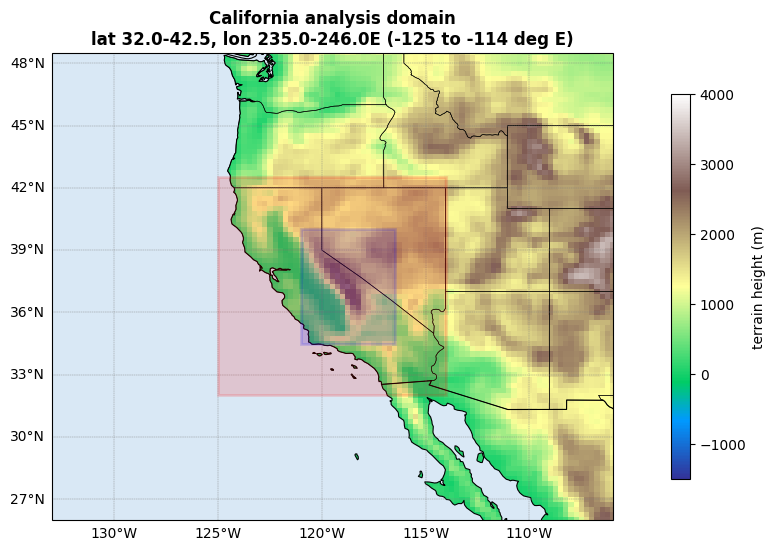

In [11]:
fig = plt.figure(figsize=(8, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([MAP_LON_W, MAP_LON_E, MAP_LAT_S, MAP_LAT_N], crs=ccrs.PlateCarree())

# terrain height background (ERA5 invariant surface geopotential)
terrain = ax.pcolormesh(
    elevation['longitude'], elevation['latitude'], elevation,
    cmap='terrain', vmin=-1500, vmax=4000,
    shading='auto', transform=ccrs.PlateCarree(), zorder=0,
)
cbar = plt.colorbar(terrain, ax=ax, orientation='vertical', shrink=0.5, pad=0.08)
cbar.set_label('terrain height (m)')

ax.add_feature(cfeature.OCEAN, facecolor='#d9e8f5', zorder=1)
ax.coastlines(resolution='50m', linewidth=0.8, zorder=2)
ax.add_feature(cfeature.BORDERS, linewidth=0.8, zorder=2)
ax.add_feature(cfeature.STATES, linewidth=0.4, edgecolor='black', zorder=2)

box = mpatches.Rectangle(
    (LON_W, LAT_S), LON_E - LON_W, LAT_N - LAT_S,
    linewidth=2, edgecolor='red', facecolor='red', alpha=0.15,
    transform=ccrs.PlateCarree(), zorder=3,
)
ax.add_patch(box)

sierra_box = mpatches.Rectangle(
    (SIERRA_LON_W, SIERRA_LAT_S), SIERRA_LON_E - SIERRA_LON_W, SIERRA_LAT_N - SIERRA_LAT_S,
    linewidth=2, edgecolor='blue', facecolor='blue', alpha=0.15,
    transform=ccrs.PlateCarree(), zorder=4,
)
ax.add_patch(sierra_box)

gl = ax.gridlines(draw_labels=True, linewidth=0.3, linestyle='--', color='gray')
gl.top_labels = False
gl.right_labels = False

ax.set_title('California analysis domain\n'
             f'lat {LAT_S}-{LAT_N}, lon {LON_W}-{LON_E}E ({LON_W-360:.0f} to {LON_E-360:.0f} deg E)',
             fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()